# TCC: Previsão de Inadimplência em Concessão de Crédito
**Metodologia:** CRISP-DM

## Fases 4 e 5: Modelagem Preditiva e Avaliação (*Modeling & Evaluation*)

Este *notebook* dá continuidade à metodologia CRISP-DM. Após o entendimento e a preparação matemática dos dados (Fases 1, 2 e 3) realizados nos arquivos anteriores, o foco agora é treinar os algoritmos de *Machine Learning* e avaliar o seu desempenho.

Com base na fundamentação do projeto, aplicaremos o **Aprendizado Sensível ao Custo** (*Cost-Sensitive Learning*) para lidar com o desbalanceamento da classe alvo (80% adimplentes / 20% inadimplentes). Iniciaremos com a Regressão Logística para estabelecer a nossa linha de base (*baseline*) e avançaremos para os métodos baseados em árvores (Random Forest e XGBoost).

### 1. Importação de Bibliotecas e Carregamento dos Dados
Nesta etapa inicial, carregamos as ferramentas matemáticas do Scikit-Learn e as matrizes otimizadas em Parquet (Treino, Validação e Teste) geradas ao final da etapa de Preparação de Dados.

In [1]:
# Importacao das bibliotecas de modelagem preditiva e metricas
import polars as pl
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    average_precision_score # PR-AUC
)

# Importacao das bibliotecas visuais para a Matriz de Confusao
import matplotlib.pyplot as plt
import seaborn as sns

# FUNCAO PADRONIZADA DE AVALIACAO
def evaluate_classification(y_true, y_pred, y_pred_proba, model_name="Modelo"):
    """Calcula as metricas e plota a Matriz de Confusao."""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    pr_auc = average_precision_score(y_true, y_pred_proba)
    
    print(f"--- Resultados: {model_name} ---")
    print(f"PR-AUC  : {pr_auc:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"Recall  : {rec:.4f}")
    print(f"Precisao: {prec:.4f}")
    print(f"Acuracia: {acc:.4f}\n")
    
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Adimplente (0)', 'Inadimplente (1)'], 
                yticklabels=['Adimplente (0)', 'Inadimplente (1)'])
    plt.ylabel('Classe Real (Actual value)')
    plt.xlabel('Classe Predita (Predicted value)')
    plt.title(f'Matriz de Confusao - {model_name}')
    plt.show()


# PREPARACAO DOS DADOS
# Carregamento otimizado dos ficheiros particionados
df_train = pl.read_parquet('DataSet_Loan/df_treino.parquet')
df_val = pl.read_parquet('DataSet_Loan/df_val.parquet')
df_test = pl.read_parquet('DataSet_Loan/df_teste.parquet')

# Separacao entre variaveis preditivas (X) e a variavel alvo (y)
X_train = df_train.drop('target').to_pandas()
y_train = df_train.select('target').to_pandas().squeeze()

X_val = df_val.drop('target').to_pandas()
y_val = df_val.select('target').to_pandas().squeeze()

X_test = df_test.drop('target').to_pandas()
y_test = df_test.select('target').to_pandas().squeeze()

## 2. Regressão Logística (*Baseline*)

A **Regressão Logística** é implementada como o modelo de linha de base (*baseline*). Por ser um algoritmo estatístico de natureza linear, o seu objetivo principal não é atingir o limite máximo de poder preditivo, mas sim estabelecer o referencial mínimo de desempenho, em especial na métrica de *Recall*, que os métodos de *ensemble learning* subsequentes deverão superar.

--- Resultados: Regressao Logistica ---
PR-AUC  : 0.3743
F1-score: 0.4268
Recall  : 0.6525
Precisao: 0.3171
Acuracia: 0.6460



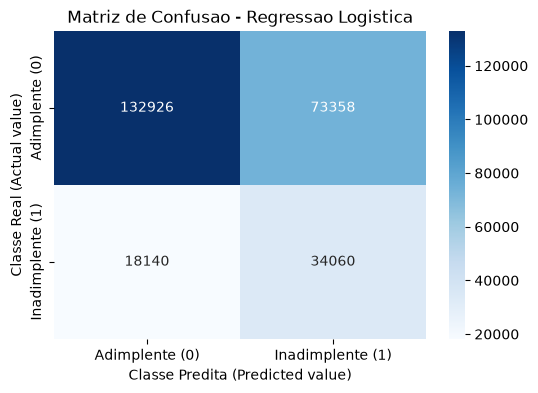

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", random_state=42, max_iter=2000)
)

log_reg.fit(X_train, y_train)

y_pred_val_lr = log_reg.predict(X_val)
y_pred_proba_val_lr = log_reg.predict_proba(X_val)[:, 1]

evaluate_classification(y_val, y_pred_val_lr, y_pred_proba_val_lr, model_name="Regressao Logistica")